# BRFSS 2017 → Cambodia STEPS Diabetes Risk Prediction
## Train on BRFSS 2017 (US) → Independent Test on Cambodia STEPS

**Pipeline:**
```
BRFSS 2017 + Cambodia STEPS
  → Feature Alignment (11 shared features)
  → BRFSS 2017 80/20 Train/Validation Split
  → StandardScaler (fit on train)  →  SMOTETomek (train only)
  → Train & Tune 5 Models (LR, RF, XGBoost, LightGBM, CatBoost)
  → Evaluate on BRFSS validation  →  Top 3 by F1  →  Soft Voting Ensemble (average)
  → Per-model Threshold Sweep (0.05–0.95) on validation
  → Select (model, threshold): highest F1 among Recall ≥ 0.70
  → Single Independent Test on Cambodia STEPS
  → SHAP XAI  →  Risk Level  →  Gemini Recommendations
```

**Models:** Logistic Regression · Random Forest · XGBoost · LightGBM · CatBoost · **Soft Voting** (average of best 3 by F1)

**Selection rule:**
> Choose the (model, threshold) pair with the **highest validation F1**, among pairs where **Diabetes Recall ≥ 0.70**.  
> If no pair reaches Recall ≥ 0.70, pick the highest-F1 pair overall and report the recall requirement was not met.

**Evaluation Metrics:** Accuracy · Precision · Recall · F1-score · Confusion Matrix

**Saves:** `best_model_2017.pkl` · `scaler_2017.pkl` · `threshold_2017.pkl` · `feature_names_2017.pkl`

## 1. Imports & Configuration

In [2]:
import warnings
warnings.filterwarnings('ignore')

import os, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from dotenv import load_dotenv
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.combine import SMOTETomek

# CatBoost is a REQUIRED model — auto-install if missing, then import.
try:
    from catboost import CatBoostClassifier
except ImportError:
    import subprocess, sys
    print('Installing catboost...')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'catboost'])
    from catboost import CatBoostClassifier

RANDOM_STATE = 42
TARGET_COL   = 'Diabetes_binary'
DATA_DIR     = '../newdata/'

RISK_COLORS = {'Low': '#4CAF50', 'Moderate': '#FF9800', 'High': '#F44336'}

FEATURE_LABELS = {
    'Sex':               'Sex',
    'Age':               'Age group',
    'Education':         'Education level',
    'HighBP':            'High blood pressure',
    'HighChol':          'High cholesterol',
    'BMI':               'BMI',
    'Smoker':            'Smoker',
    'PhysActivity':      'Physical activity',
    'Fruits':            'Fruit consumption',
    'Veggies':           'Vegetable consumption',
    'HvyAlcoholConsump': 'Heavy alcohol use',
}

FEATURE_GROUPS = {
    'Demographic':   ['Sex', 'Age', 'Education'],
    'Health Status': ['HighBP', 'HighChol', 'BMI'],
    'Lifestyle':     ['Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump'],
}

print('Libraries loaded.')

Libraries loaded.


## 2. Gemini API Setup

In [3]:
from google import genai

load_dotenv('../.env')
GEMINI_API_KEY = os.getenv('GEMINI_API_KEY', '')
gemini_client  = genai.Client(api_key=GEMINI_API_KEY) if GEMINI_API_KEY else None

def get_gemini_recommendations(prob, risk, patient_profile, top_risk_factors, protective_factors):
    payload = {
        'risk_probability': round(float(prob), 2), 'risk_level': risk,
        'patient_profile': patient_profile, 'top_risk_factors': top_risk_factors,
        'protective_factors': protective_factors,
        'instruction': 'Provide simple lifestyle education only. Do not diagnose.',
    }
    prompt = (
        'You are a friendly health educator. Based on this diabetes risk assessment, '
        'provide lifestyle guidance.\n\n' + json.dumps(payload, indent=2)
        + '\n\nRespond ONLY in this JSON (no markdown):\n'
        '{"explanation": "...", "recommendations": ["...","...","...","..."], '
        '"safety_reminder": "..."}'
    )
    try:
        r = gemini_client.models.generate_content(model='gemini-1.5-flash', contents=prompt)
        text = r.text.strip()
        if '```' in text:
            text = text.split('```')[1]
            if text.startswith('json'): text = text[4:]
        return json.loads(text.strip())
    except Exception:
        return {
            'explanation': f'Predicted risk: {prob*100:.0f}% ({risk} level).',
            'recommendations': [
                'Maintain a balanced diet rich in vegetables and whole grains',
                'Engage in at least 150 minutes of moderate exercise per week',
                'Monitor blood pressure and blood glucose regularly',
                'Consult a healthcare professional for personalised advice',
            ],
            'safety_reminder': 'For educational awareness only — not a medical diagnosis.',
        }

print(f'Gemini client ready: {"Yes" if gemini_client else "No API key"}')

Gemini client ready: Yes


## 3. Feature Alignment

BRFSS 2017 and STEPS share **11 common features** grouped into three categories.

| Group | Features |
|---|---|
| **Demographic** | Sex, Age, Education |
| **Health Status** | HighBP, HighChol, BMI |
| **Lifestyle** | Smoker, PhysActivity, Fruits, Veggies, HvyAlcoholConsump |

| Alignment Note | Detail |
|---|---|
| **Age encoding** | BRFSS = ordinal group 1–13 · STEPS = actual years → converted via `steps_age_to_brfss_group()` |
| **Excluded** | Income excluded — not consistently available in STEPS |

In [4]:
TARGET_ALIGNED = [
    'Sex', 'Age', 'Education',                              # Demographic
    'HighBP', 'HighChol', 'BMI',                           # Health Status
    'Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump',  # Lifestyle
]

def steps_age_to_brfss_group(age):
    """Map continuous age (years) → BRFSS age group (1–13)."""
    bins   = [0, 24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 74, 79, 999]
    groups = list(range(1, 14))
    for i, (lo, hi) in enumerate(zip(bins, bins[1:])):
        if lo < age <= hi:
            return groups[i]
    return 13

print('Alignment functions defined.')
print(f'Target aligned feature set ({len(TARGET_ALIGNED)}): {TARGET_ALIGNED}')

Alignment functions defined.
Target aligned feature set (11): ['Sex', 'Age', 'Education', 'HighBP', 'HighChol', 'BMI', 'Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump']


## 4. Data Loading

In [5]:
print('Loading BRFSS 2017 data...')
df_brfss = pd.read_csv(DATA_DIR + 'brfss2017_clean_binary.csv')
print(f'  BRFSS 2017: {df_brfss.shape}  |  diabetes rate: {df_brfss[TARGET_COL].mean()*100:.1f}%')

Loading BRFSS 2017 data...
  BRFSS 2017: (275746, 22)  |  diabetes rate: 16.0%


In [6]:
print('Loading Cambodia STEPS data...')
df_steps = pd.read_csv(DATA_DIR + 'cambodia_diabetes_final_clean.csv')
print(f'  STEPS: {df_steps.shape}  |  diabetes rate: {df_steps[TARGET_COL].mean()*100:.1f}%')
print(f'  STEPS columns: {df_steps.columns.tolist()}')

# Convert Age: actual years → BRFSS age group (1–13)
if 'Age' in df_steps.columns:
    df_steps['Age'] = df_steps['Age'].apply(steps_age_to_brfss_group)
    print('  Age converted: continuous years → BRFSS group (1–13)')

Loading Cambodia STEPS data...
  STEPS: (873, 15)  |  diabetes rate: 14.0%
  STEPS columns: ['Diabetes_binary', 'Sex', 'Age', 'Education', 'BMI', 'Waist_cm', 'HighBP', 'HighChol', 'Smoker', 'AlcoholUse', 'HvyAlcoholConsump', 'PhysActivity', 'SedentaryMinutes', 'Fruits', 'Veggies']
  Age converted: continuous years → BRFSS group (1–13)


Aligned features confirmed (11): ['Sex', 'Age', 'Education', 'HighBP', 'HighChol', 'BMI', 'Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump']


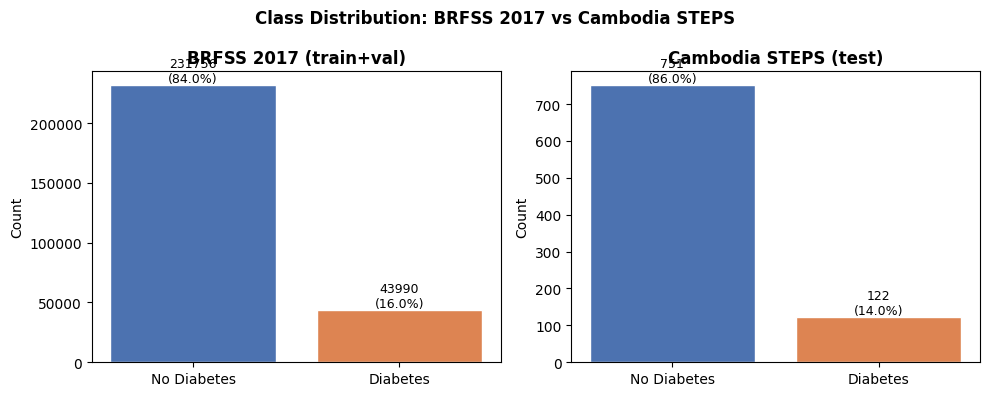

In [7]:
brfss_cols = [c for c in df_brfss.columns if c != TARGET_COL]
steps_cols = [c for c in df_steps.columns if c != TARGET_COL]

ALIGNED_FEATURES = [f for f in TARGET_ALIGNED if f in brfss_cols and f in steps_cols]
missing_brfss = [f for f in TARGET_ALIGNED if f not in brfss_cols]
missing_steps = [f for f in TARGET_ALIGNED if f not in steps_cols]

print(f'Aligned features confirmed ({len(ALIGNED_FEATURES)}): {ALIGNED_FEATURES}')
if missing_brfss: print(f'  Missing from BRFSS: {missing_brfss}')
if missing_steps: print(f'  Missing from STEPS: {missing_steps}')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, df_) in zip(axes, [('BRFSS 2017 (train+val)', df_brfss), ('Cambodia STEPS (test)', df_steps)]):
    counts = df_[TARGET_COL].value_counts().sort_index()
    ax.bar(['No Diabetes','Diabetes'], counts.values, color=['#4C72B0','#DD8452'], edgecolor='white')
    for i, v in enumerate(counts.values):
        ax.text(i, v + counts.max()*0.01, f'{v}\n({v/len(df_)*100:.1f}%)', ha='center', fontsize=9)
    ax.set_title(name, fontweight='bold')
    ax.set_ylabel('Count')
plt.suptitle('Class Distribution: BRFSS 2017 vs Cambodia STEPS', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

## 5. BRFSS 2017 Split — Stratified 80/20

- **Train (80%)**: model fitting + SMOTETomek
- **Validation (20%)**: model selection by F1 + threshold tuning
- **Cambodia STEPS**: independent test set — never used during training or selection

                               Rows  Diabetes  No Diabetes  % Positive
Split                                                                 
Train — BRFSS 2017 80%       220596     35192       185404        16.0
Validation — BRFSS 2017 20%   55150      8798        46352        16.0
Test — Cambodia STEPS           873       122          751        14.0


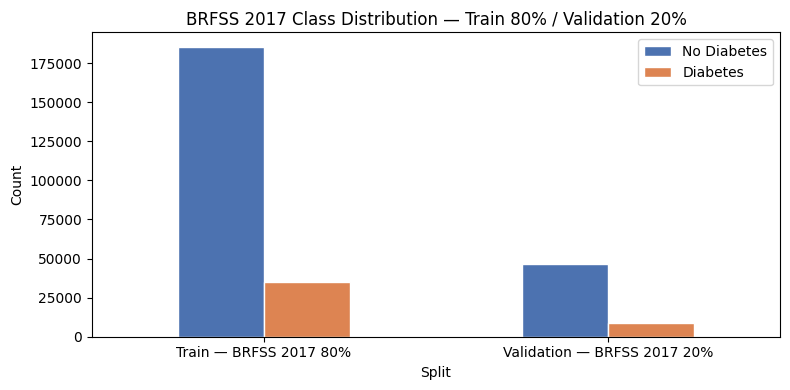

In [8]:
X_brfss = df_brfss[ALIGNED_FEATURES]
y_brfss = df_brfss[TARGET_COL]

X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_brfss, y_brfss, test_size=0.20, stratify=y_brfss, random_state=RANDOM_STATE
)

# STEPS independent test
X_test_raw = df_steps[ALIGNED_FEATURES]
y_test     = df_steps[TARGET_COL]

summary = pd.DataFrame([
    {'Split': n, 'Rows': len(s), 'Diabetes': int(s.sum()),
     'No Diabetes': int((s==0).sum()), '% Positive': round(s.mean()*100, 1)}
    for n, s in [('Train — BRFSS 2017 80%', y_train),
                 ('Validation — BRFSS 2017 20%', y_val),
                 ('Test — Cambodia STEPS', y_test)]
]).set_index('Split')
print(summary)

# Plot ONLY the BRFSS 80/20 split. Cambodia STEPS is a SEPARATE external test set
# (not part of this split) and is shown in the BRFSS-vs-STEPS comparison above.
brfss_split = summary.loc[
    ['Train — BRFSS 2017 80%', 'Validation — BRFSS 2017 20%'],
    ['No Diabetes', 'Diabetes']
]
brfss_split.plot(
    kind='bar', figsize=(8, 4), color=['#4C72B0', '#DD8452'], edgecolor='white'
)
plt.title('BRFSS 2017 Class Distribution — Train 80% / Validation 20%')
plt.ylabel('Count'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 6. Preprocessing — StandardScaler

Fit on BRFSS 2017 train only. Applied to BRFSS 2017 validation and Cambodia STEPS test.

In [9]:
scaler    = StandardScaler()
X_train_s = scaler.fit_transform(X_train_raw)
X_val_s   = scaler.transform(X_val_raw)
X_test_s  = scaler.transform(X_test_raw)
print(f'Scaled — Train: {X_train_s.shape}  Val: {X_val_s.shape}  Test (STEPS): {X_test_s.shape}')

Scaled — Train: (220596, 11)  Val: (55150, 11)  Test (STEPS): (873, 11)


## 7. Class Imbalance Handling — SMOTETomek

**SMOTETomek** = SMOTE (synthetic minority oversampling) + Tomek links (removes borderline ambiguous pairs).  
Applied **only to BRFSS 2017 training set**. Validation and STEPS test remain untouched real data.

                 Before  After SMOTETomek
Diabetes_binary                          
No Diabetes      185404            182354
Diabetes          35192            182354


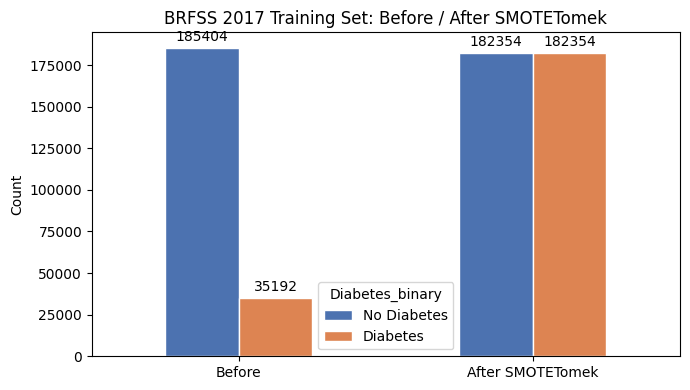

In [10]:
smt = SMOTETomek(random_state=RANDOM_STATE)
X_train_bal, y_train_bal = smt.fit_resample(X_train_s, y_train)

before = pd.Series(y_train).value_counts().rename({0:'No Diabetes', 1:'Diabetes'})
after  = pd.Series(y_train_bal).value_counts().rename({0:'No Diabetes', 1:'Diabetes'})
bal_df = pd.DataFrame({'Before': before, 'After SMOTETomek': after})
print(bal_df)

ax = bal_df.T.plot(kind='bar', figsize=(7, 4), color=['#4C72B0','#DD8452'], edgecolor='white')
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3)
plt.title('BRFSS 2017 Training Set: Before / After SMOTETomek')
plt.ylabel('Count'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 8. Model Training & Hyperparameter Tuning — 5 Models

All trained on SMOTETomek-balanced BRFSS 2017 data. No epochs — these are classic ML models.
The **Soft Voting** ensemble (average of the best 3 by validation F1) is built in the next section.

| # | Model | Strategy |
|---|---|---|
| 1 | Logistic Regression | Fixed hyperparams, balanced class weights |
| 2 | Random Forest | RandomizedSearchCV — 30 iter, 3-fold, F1 |
| 3 | XGBoost | RandomizedSearchCV — 30 iter, 3-fold, F1 |
| 4 | LightGBM | RandomizedSearchCV — 30 iter, 3-fold, F1 |
| 5 | CatBoost | RandomizedSearchCV — 15 iter, 3-fold, F1 |

In [11]:
individual_models = {}
best_params       = {}

# 1. Logistic Regression (fixed, balanced class weights)
individual_models['Logistic Regression'] = LogisticRegression(
    max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE
)
individual_models['Logistic Regression'].fit(X_train_bal, y_train_bal)
best_params['Logistic Regression'] = {'class_weight': 'balanced', 'max_iter': 2000}
print('Trained: Logistic Regression')

neg = int((y_train_bal == 0).sum())
pos = int((y_train_bal == 1).sum())
scale_pos = neg / pos if pos > 0 else 1.0

# 2–5. Tuned models — each entry: (estimator, param_dist, n_iter)
search_spaces = {
    'Random Forest': (
        RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
        {'n_estimators': [100,200,300,500], 'max_depth': [None,8,12,16],
         'min_samples_split': [2,5,10], 'min_samples_leaf': [1,2,4]},
        30
    ),
    'XGBoost': (
        XGBClassifier(scale_pos_weight=scale_pos, eval_metric='logloss',
                      random_state=RANDOM_STATE, n_jobs=-1, tree_method='hist'),
        {'n_estimators': [100,200,300,500], 'max_depth': [3,5,7,9],
         'learning_rate': [0.03,0.05,0.1,0.2], 'subsample': [0.7,0.8,1.0],
         'colsample_bytree': [0.7,0.8,1.0]},
        30
    ),
    'LightGBM': (
        LGBMClassifier(is_unbalance=True, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
        {'n_estimators': [100,200,300,500], 'max_depth': [-1,5,10,15],
         'learning_rate': [0.03,0.05,0.1,0.2], 'num_leaves': [31,63,127,255]},
        30
    ),
    'CatBoost': (
        CatBoostClassifier(auto_class_weights='Balanced', verbose=0, random_state=RANDOM_STATE),
        {'depth': [4,6,8], 'learning_rate': [0.03,0.05,0.1],
         'iterations': [200,300,400], 'l2_leaf_reg': [1,3,5]},
        15
    ),
}

for name, (estimator, param_dist, n_iter) in search_spaces.items():
    search = RandomizedSearchCV(
        estimator, param_dist, n_iter=n_iter, cv=3,
        scoring='f1', random_state=RANDOM_STATE, n_jobs=-1
    )
    search.fit(X_train_bal, y_train_bal)
    individual_models[name] = search.best_estimator_
    best_params[name]       = search.best_params_
    print(f'Tuned {name:<20s} |  best CV F1: {search.best_score_:.4f}')
    print(f'  params: {search.best_params_}')

print(f'\nAll {len(individual_models)} models trained and tuned (incl. CatBoost).')

Trained: Logistic Regression
Tuned Random Forest        |  best CV F1: 0.8473
  params: {'n_estimators': 500, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': None}
Tuned XGBoost              |  best CV F1: 0.8160
  params: {'subsample': 1.0, 'n_estimators': 200, 'max_depth': 9, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Tuned LightGBM             |  best CV F1: 0.8419
  params: {'num_leaves': 127, 'n_estimators': 500, 'max_depth': -1, 'learning_rate': 0.2}
Tuned CatBoost             |  best CV F1: 0.8219
  params: {'learning_rate': 0.05, 'l2_leaf_reg': 1, 'iterations': 200, 'depth': 6}

All 5 models trained and tuned (incl. CatBoost).


## 9. Validation on BRFSS 2017 + Build Soft Voting

**Step 4** — Evaluate the **5 models** on the BRFSS validation set at 0.5 (Accuracy · Precision · Recall · F1).
**Build ensemble** — take the **top 3 by validation F1** and build a **Soft Voting** ensemble (averages their predicted probabilities), fit on the BRFSS training set.

The full candidate set for threshold tuning = **5 base models + Soft Voting** (6 total).

Base model validation metrics @ threshold 0.50 (sorted by F1):
                     Accuracy  Precision  Recall      F1
XGBoost                0.7745     0.3707  0.5924  0.4560
Logistic Regression    0.7044     0.3179  0.7445  0.4455
CatBoost               0.8008     0.4004  0.4999  0.4446
Random Forest          0.7850     0.3548  0.4249  0.3867
LightGBM               0.8041     0.3849  0.3812  0.3831

Top 3 by validation F1 -> Soft Voting members: ['XGBoost', 'Logistic Regression', 'CatBoost']

All candidates — validation metrics @ threshold 0.50 (sorted by F1):
                     Accuracy  Precision  Recall      F1
Soft Voting            0.7661     0.3638  0.6221  0.4591
XGBoost                0.7745     0.3707  0.5924  0.4560
Logistic Regression    0.7044     0.3179  0.7445  0.4455
CatBoost               0.8008     0.4004  0.4999  0.4446
Random Forest          0.7850     0.3548  0.4249  0.3867
LightGBM               0.8041     0.3849  0.3812  0.3831


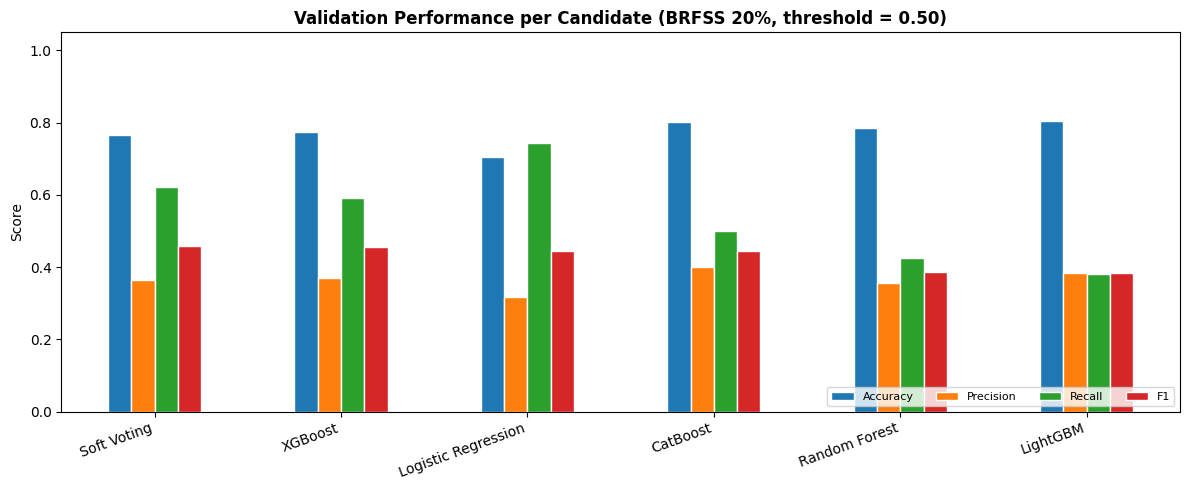

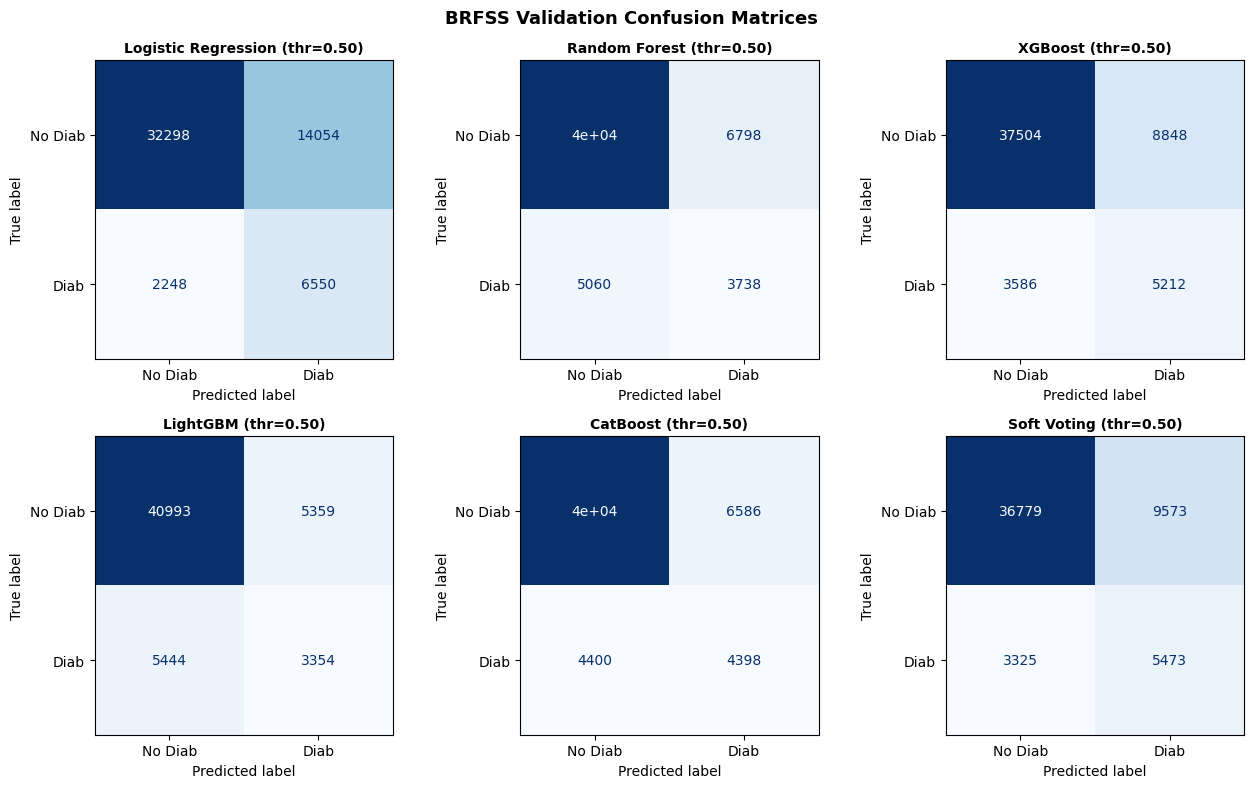

In [12]:
def evaluate(model, X, y, threshold=0.5):
    """Accuracy / Precision / Recall / F1 at a given threshold."""
    proba = model.predict_proba(X)[:, 1]
    pred  = (proba >= threshold).astype(int)
    return {
        'Accuracy':  round(accuracy_score(y, pred), 4),
        'Precision': round(precision_score(y, pred, zero_division=0), 4),
        'Recall':    round(recall_score(y, pred, zero_division=0), 4),
        'F1':        round(f1_score(y, pred, zero_division=0), 4),
    }

METRIC_COLS = ['Accuracy', 'Precision', 'Recall', 'F1']

# ── Step 4: evaluate the 5 base models on BRFSS validation @0.5 ───────────────
base_results = {n: evaluate(m, X_val_s, y_val) for n, m in individual_models.items()}
val_base_df  = pd.DataFrame(base_results).T[METRIC_COLS].sort_values('F1', ascending=False)
print('Base model validation metrics @ threshold 0.50 (sorted by F1):')
print(val_base_df.to_string())

# ── Top 3 by validation F1 -> Soft Voting ensemble (average of probabilities) ─
top3_names = val_base_df.nlargest(3, 'F1').index.tolist()
print(f'\nTop 3 by validation F1 -> Soft Voting members: {top3_names}')

ENSEMBLE_LABEL = 'Soft Voting'
voting = VotingClassifier(
    estimators=[(n.lower().replace(' ', '_'), individual_models[n]) for n in top3_names],
    voting='soft', n_jobs=1
)
voting.fit(X_train_bal, y_train_bal)   # fit on the same balanced BRFSS training data

# ── Full candidate set = 5 base + Soft Voting ────────────────────────────────
final_models = dict(individual_models)
final_models[ENSEMBLE_LABEL] = voting

val_results = {n: evaluate(m, X_val_s, y_val) for n, m in final_models.items()}
val_df = pd.DataFrame(val_results).T[METRIC_COLS].sort_values('F1', ascending=False)
print('\nAll candidates — validation metrics @ threshold 0.50 (sorted by F1):')
print(val_df.to_string())

# ── Bar chart ────────────────────────────────────────────────────────────────
ax = val_df.plot(kind='bar', figsize=(12, 5), edgecolor='white')
ax.set_title('Validation Performance per Candidate (BRFSS 20%, threshold = 0.50)', fontweight='bold')
ax.set_ylabel('Score'); ax.set_ylim(0, 1.05)
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right')
ax.legend(loc='lower right', ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

# ── Confusion matrix per candidate (2x3 grid) ────────────────────────────────
n_models = len(final_models)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax_, (name, model) in zip(axes.ravel(), final_models.items()):
    pred = (model.predict_proba(X_val_s)[:, 1] >= 0.5).astype(int)
    cm   = confusion_matrix(y_val, pred)
    ConfusionMatrixDisplay(cm, display_labels=['No Diab', 'Diab']).plot(
        ax=ax_, cmap='Blues', colorbar=False)
    ax_.set_title(f'{name} (thr=0.50)', fontsize=10, fontweight='bold')
for ax_ in axes.ravel()[n_models:]:
    ax_.axis('off')
plt.suptitle('BRFSS Validation Confusion Matrices', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

## 10. Joint Model × Threshold Selection

**Step 5.** For **every candidate** (5 base + Soft Voting), sweep thresholds **0.05 → 0.95** on the BRFSS validation set and record Accuracy / Precision / Recall / F1.

**Selection rule:**
> Choose the (model, threshold) pair with the **highest validation F1**, among pairs where **Diabetes Recall ≥ 0.70**.  
> If no pair reaches Recall ≥ 0.70, pick the highest-F1 pair overall and report the recall requirement was not met.

Selection uses the **validation set only** — Cambodia STEPS is never consulted here.

  SELECTED (model, threshold) PAIR  —  validation only
  Best model      : Soft Voting
  Best threshold  : 0.43
  Recall >= 0.7 : MET
  Val F1          : 0.4515  <- selection metric
  Val Recall      : 0.7046  <- clinical priority
  Val Accuracy    : 0.7269
  Val Precision   : 0.3322

Top 10 (model, threshold) pairs by F1 among Recall >= 0.7:
              Model  Threshold Accuracy Precision Recall     F1
        Soft Voting       0.43   0.7269    0.3322 0.7046 0.4515
Logistic Regression       0.53   0.7229    0.3295 0.7122 0.4505
        Soft Voting       0.42   0.7207    0.3281 0.7163 0.4500
Logistic Regression       0.52   0.7174    0.3262 0.7238 0.4497
           CatBoost       0.34   0.7232    0.3291 0.7081 0.4494
            XGBoost       0.41   0.7254    0.3303 0.7018 0.4491
        Soft Voting       0.41   0.7142    0.3239 0.7285 0.4485
Logistic Regression       0.51   0.7112    0.3223 0.7348 0.4481
            XGBoost       0.40   0.7196    0.3264 0.7120 0.4476
           CatB

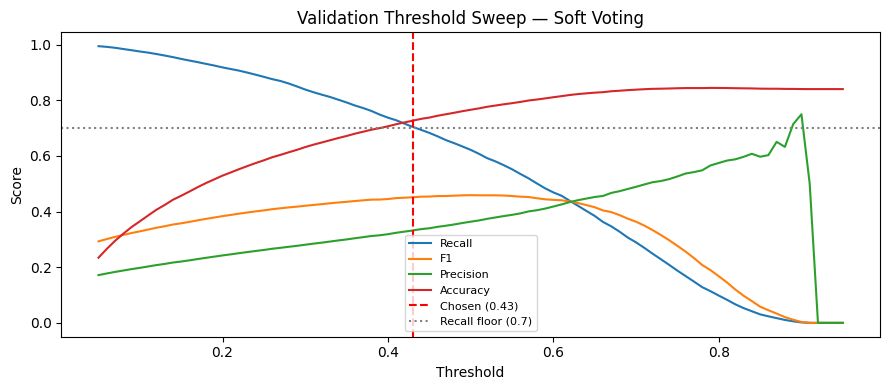

In [13]:
RECALL_FLOOR = 0.70
THRESHOLDS   = np.arange(0.05, 0.96, 0.01)

# ── Sweep every candidate x every threshold on the BRFSS VALIDATION set ───────
sweep_rows = {}
for name, model in final_models.items():
    proba = model.predict_proba(X_val_s)[:, 1]
    for t in THRESHOLDS:
        pred = (proba >= t).astype(int)
        sweep_rows[(name, round(float(t), 2))] = {
            'Accuracy':  accuracy_score(y_val, pred),
            'Precision': precision_score(y_val, pred, zero_division=0),
            'Recall':    recall_score(y_val, pred, zero_division=0),
            'F1':        f1_score(y_val, pred, zero_division=0),
        }
sweep_df = pd.DataFrame(sweep_rows).T
sweep_df.index.names = ['Model', 'Threshold']
sweep_df = sweep_df.reset_index()

# ── Selection rule: highest F1 among Recall >= 0.70 ──────────────────────────
qualified = sweep_df[sweep_df['Recall'] >= RECALL_FLOOR]
if len(qualified) > 0:
    best_row   = qualified.sort_values('F1', ascending=False).iloc[0]
    recall_met = True
else:
    best_row   = sweep_df.sort_values('F1', ascending=False).iloc[0]
    recall_met = False
    print(f'WARNING: no (model, threshold) pair reached Recall >= {RECALL_FLOOR}.')
    print('Falling back to the highest-F1 pair overall.')

best_name        = best_row['Model']
chosen_threshold = float(best_row['Threshold'])
best_model       = final_models[best_name]
proba_val        = best_model.predict_proba(X_val_s)[:, 1]   # used by the risk-level check below

print('=' * 60)
print('  SELECTED (model, threshold) PAIR  —  validation only')
print('=' * 60)
print(f'  Best model      : {best_name}')
print(f'  Best threshold  : {chosen_threshold:.2f}')
print(f'  Recall >= {RECALL_FLOOR} : {"MET" if recall_met else "NOT MET (fallback to max-F1)"}')
print(f'  Val F1          : {best_row["F1"]:.4f}  <- selection metric')
print(f'  Val Recall      : {best_row["Recall"]:.4f}  <- clinical priority')
print(f'  Val Accuracy    : {best_row["Accuracy"]:.4f}')
print(f'  Val Precision   : {best_row["Precision"]:.4f}')

print(f'\nTop 10 (model, threshold) pairs by F1'
      + (f' among Recall >= {RECALL_FLOOR}:' if recall_met else ' (overall, floor not met):'))
ranked = (qualified if recall_met else sweep_df).sort_values('F1', ascending=False).head(10)
print(ranked.to_string(index=False,
      formatters={c: '{:.4f}'.format for c in ['Accuracy', 'Precision', 'Recall', 'F1']}))

# ── Plot the threshold sweep for the SELECTED model ──────────────────────────
sel = sweep_df[sweep_df['Model'] == best_name].sort_values('Threshold')
fig, ax = plt.subplots(figsize=(9, 4))
for col in ['Recall', 'F1', 'Precision', 'Accuracy']:
    ax.plot(sel['Threshold'], sel[col], label=col)
ax.axvline(chosen_threshold, color='red', linestyle='--', lw=1.5, label=f'Chosen ({chosen_threshold:.2f})')
ax.axhline(RECALL_FLOOR, color='gray', linestyle=':', label=f'Recall floor ({RECALL_FLOOR})')
ax.set_xlabel('Threshold'); ax.set_ylabel('Score')
ax.set_title(f'Validation Threshold Sweep — {best_name}')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [14]:
# ── Risk Level Check on Validation Set ────────────────────────────────
# This checks whether Low / Moderate / High risk levels make sense.

def risk_label(prob):
    if prob < chosen_threshold:
        return "Low"
    elif prob < 0.70:
        return "Moderate"
    else:
        return "High"

val_check = pd.DataFrame({
    "Probability": proba_val,
    "Actual": y_val
})

val_check["Risk_Level"] = val_check["Probability"].apply(risk_label)

risk_summary = val_check.groupby("Risk_Level").agg(
    Count=("Actual", "count"),
    Actual_Diabetes_Count=("Actual", "sum"),
    Actual_Diabetes_Rate=("Actual", "mean")
)

risk_summary = risk_summary.reindex(["Low", "Moderate", "High"])
risk_summary["Actual_Diabetes_Rate_%"] = (
    risk_summary["Actual_Diabetes_Rate"] * 100
).round(2)

print("\nValidation Risk Level Check:")
print(risk_summary)


Validation Risk Level Check:
            Count  Actual_Diabetes_Count  Actual_Diabetes_Rate  \
Risk_Level                                                       
Low         36489                   2599              0.071227   
Moderate    13454                   3652              0.271443   
High         5207                   2547              0.489149   

            Actual_Diabetes_Rate_%  
Risk_Level                          
Low                           7.12  
Moderate                     27.14  
High                         48.91  


## 11. Final Independent Test — Cambodia STEPS

The best model + chosen threshold are applied to Cambodia STEPS **for the first time**.  
This set was never used in training, validation, or model selection.

  INDEPENDENT TEST — Cambodia STEPS (once)
  Model     : Soft Voting
  Threshold : 0.43
  Train data: BRFSS 2017 only
  Features  : 11 (['Sex', 'Age', 'Education', 'HighBP', 'HighChol', 'BMI', 'Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump'])

  Recall       0.7623 <- clinical priority
  Precision    0.2058
  Accuracy     0.5556
  F1           0.3240 <- selection metric

              precision    recall  f1-score   support

 No Diabetes       0.93      0.52      0.67       751
    Diabetes       0.21      0.76      0.32       122

    accuracy                           0.56       873
   macro avg       0.57      0.64      0.50       873
weighted avg       0.83      0.56      0.62       873



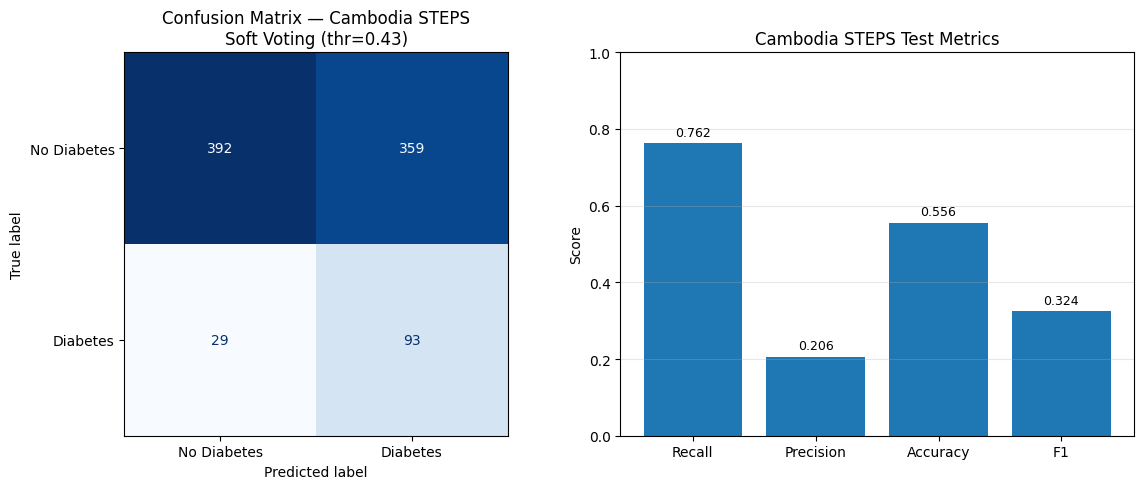


Val (@chosen threshold) vs Test Comparison:
           Validation (BRFSS 2017)  Test (STEPS)
Recall                      0.7046        0.7623
F1                          0.4515        0.3240
Accuracy                    0.7269        0.5556
Precision                   0.3322        0.2058


In [15]:
proba_test = best_model.predict_proba(X_test_s)[:, 1]
y_pred     = (proba_test >= chosen_threshold).astype(int)

test_metrics = {
    'Recall':    recall_score(y_test, y_pred, zero_division=0),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Accuracy':  accuracy_score(y_test, y_pred),
    'F1':        f1_score(y_test, y_pred, zero_division=0),
}
print('=' * 56)
print('  INDEPENDENT TEST — Cambodia STEPS (once)')
print('=' * 56)
print(f'  Model     : {best_name}')
print(f'  Threshold : {chosen_threshold:.2f}')
print(f'  Train data: BRFSS 2017 only')
print(f'  Features  : {len(ALIGNED_FEATURES)} ({ALIGNED_FEATURES})')
print()
for k, v in test_metrics.items():
    marker = ' <- clinical priority' if k == 'Recall' else (' <- selection metric' if k == 'F1' else '')
    print(f'  {k:<12s} {v:.4f}{marker}')
print()
print(classification_report(y_test, y_pred, target_names=['No Diabetes', 'Diabetes'], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=['No Diabetes', 'Diabetes']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — Cambodia STEPS\n{best_name} (thr={chosen_threshold:.2f})')

metric_order  = ['Recall', 'Precision', 'Accuracy', 'F1']
metric_values = [test_metrics[m] for m in metric_order]
axes[1].bar(metric_order, metric_values)
axes[1].set_ylim(0, 1); axes[1].set_ylabel('Score')
axes[1].set_title('Cambodia STEPS Test Metrics')
axes[1].grid(axis='y', alpha=0.3)
for i, v in enumerate(metric_values):
    axes[1].text(i, v + 0.02, f'{v:.3f}', ha='center', fontsize=9)
plt.tight_layout(); plt.show()

# Validation (at chosen threshold) vs Test comparison
comparison = pd.DataFrame({
    'Validation (BRFSS 2017)': pd.Series({k: best_row[k] for k in ['Recall', 'F1', 'Accuracy', 'Precision']}),
    'Test (STEPS)':            pd.Series({k: test_metrics[k] for k in ['Recall', 'F1', 'Accuracy', 'Precision']}),
})
print('\nVal (@chosen threshold) vs Test Comparison:')
print(comparison.round(4).to_string())

## 12. XAI — SHAP Explainability

SHAP computed on Cambodia STEPS test set.

SHAP computed on: XGBoost (SHAP proxy — best tree)
SHAP values shape: (873, 11)


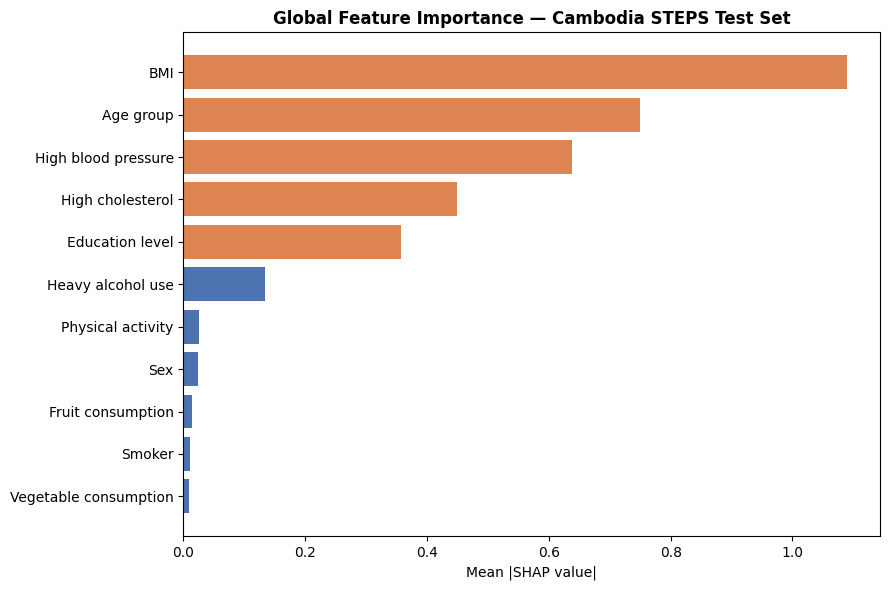

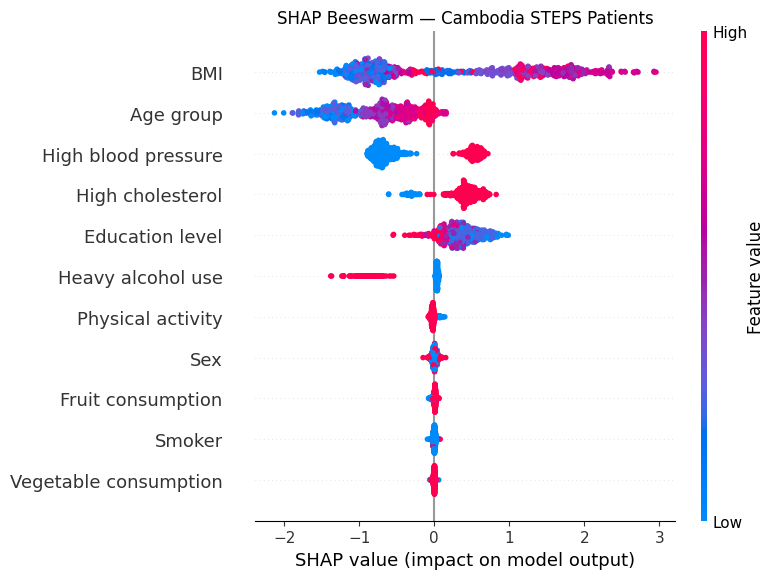

In [17]:
TREE_MODELS = ['LightGBM', 'XGBoost', 'Random Forest', 'CatBoost']

if best_name in TREE_MODELS:
    shap_model = best_model
    shap_model_name = best_name
else:
    # best model isn't a single tree model (e.g. Logistic Regression / Soft Voting)
    # -> use the best tree model (by validation F1) for SHAP
    tree_candidates = [n for n in TREE_MODELS if n in individual_models]
    shap_model_name = val_df.loc[val_df.index.isin(tree_candidates), 'F1'].idxmax()
    shap_model = individual_models[shap_model_name]
    shap_model_name += ' (SHAP proxy — best tree)'

print(f'SHAP computed on: {shap_model_name}')

explainer   = shap.TreeExplainer(shap_model)
X_test_s_df = pd.DataFrame(X_test_s, columns=ALIGNED_FEATURES)

shap_values = explainer(X_test_s_df)

if shap_values.values.ndim == 3:
    sv = shap_values[:, :, 1]
else:
    sv = shap_values

display_names = [FEATURE_LABELS.get(f, f) for f in ALIGNED_FEATURES]

sv_named = shap.Explanation(
    values=sv.values,
    base_values=sv.base_values,
    data=sv.data,
    feature_names=display_names
)

print(f'SHAP values shape: {sv_named.values.shape}')


# Global Feature Importance
mean_shap = (
    pd.Series(np.abs(sv_named.values).mean(axis=0), index=display_names)
    .sort_values(ascending=True)
)

palette = ['#DD8452' if v > mean_shap.median() else '#4C72B0' for v in mean_shap]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(mean_shap.index, mean_shap.values, color=palette)
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('Global Feature Importance — Cambodia STEPS Test Set', fontweight='bold')
plt.tight_layout()
plt.show()

# SHAP Beeswarm
shap.plots.beeswarm(sv_named, max_display=12, show=False)
plt.title('SHAP Beeswarm — Cambodia STEPS Patients')
plt.tight_layout()
plt.show()

## 13. Risk Level Output

| Risk Level | Probability |
|---|---|
| Low | < 30 % |
| Moderate | 30 % – 70 % |
| High | ≥ 70 % |

Risk distribution — Cambodia STEPS:
Risk Level
Low         299
Moderate    401
High        173
Name: count, dtype: int64


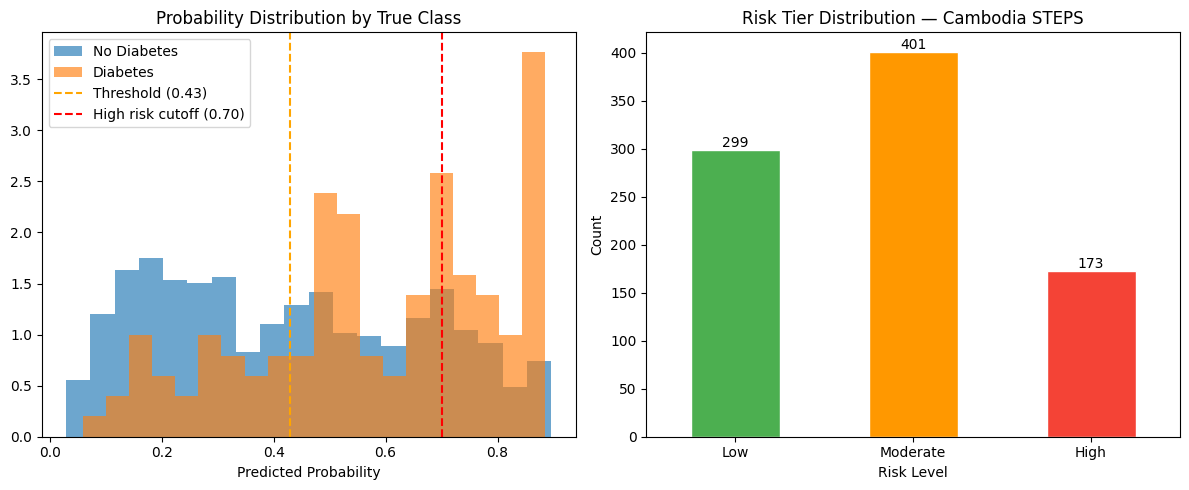

In [ ]:
def risk_label(prob):
    return 'High' if prob >= 0.70 else ('Moderate' if prob >= 0.30 else 'Low')

test_report = X_test_raw.copy().reset_index(drop=True)
test_report['True Label']  = y_test.values
test_report['Probability'] = proba_test.round(3)
test_report['Risk Level']  = test_report['Probability'].apply(risk_label)
test_report['Prediction']  = y_pred

risk_dist = test_report['Risk Level'].value_counts().reindex(['Low','Moderate','High'])
print('Risk distribution — Cambodia STEPS:')
print(risk_dist)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for lab, grp in test_report.groupby('True Label'):
    axes[0].hist(grp['Probability'], bins=20, alpha=0.65,
                 label=['No Diabetes','Diabetes'][int(lab)], density=True)
axes[0].axvline(chosen_threshold, color='orange', linestyle='--', label=f'Threshold ({chosen_threshold:.2f})')
axes[0].axvline(0.70, color='red', linestyle='--', label='High risk cutoff (0.70)')
axes[0].set_xlabel('Predicted Probability')
axes[0].set_title('Probability Distribution by True Class')
axes[0].legend()

risk_dist.plot(kind='bar', ax=axes[1],
               color=[RISK_COLORS[r] for r in risk_dist.index], edgecolor='white')
for p in axes[1].patches:
    axes[1].annotate(str(int(p.get_height())),
                     (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
axes[1].set_title('Risk Tier Distribution — Cambodia STEPS')
axes[1].set_ylabel('Count')
axes[1].set_xticklabels(risk_dist.index, rotation=0)
plt.tight_layout(); plt.show()

## 14. Actionable Recommendations — Patient Dashboard

High-risk patient: #800


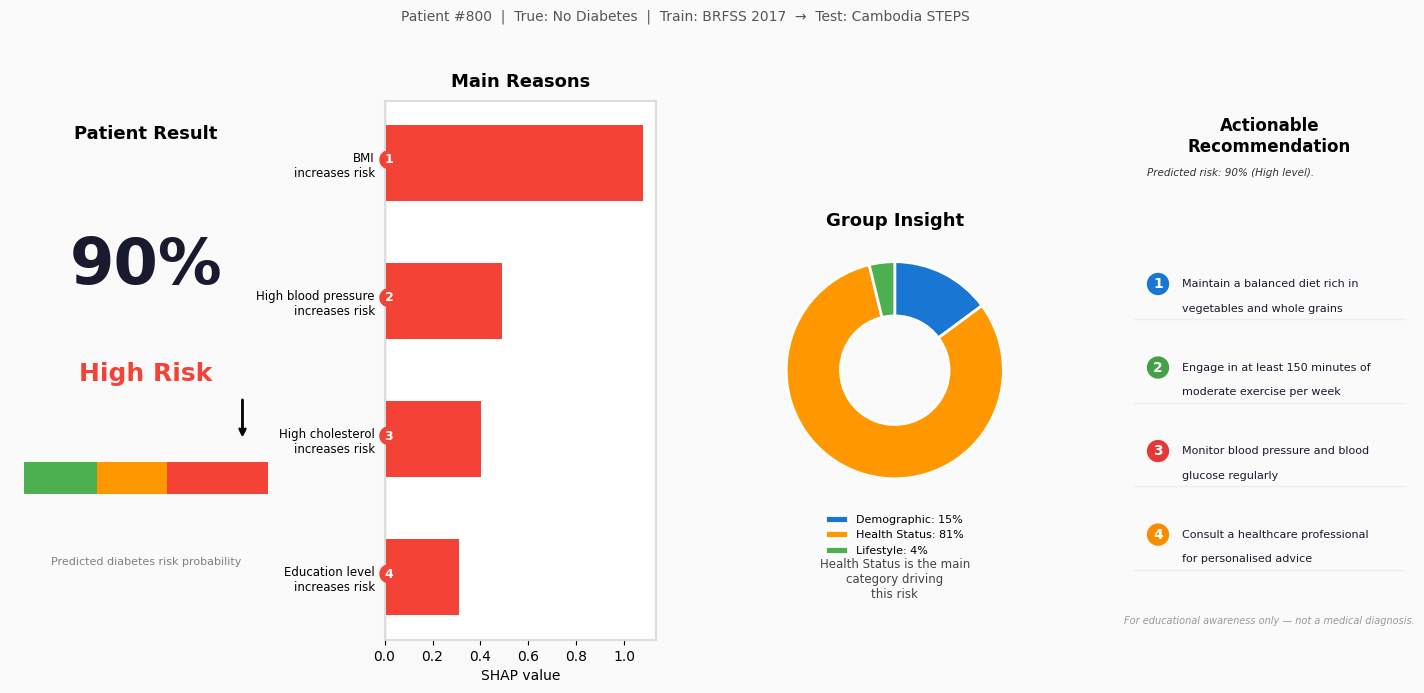

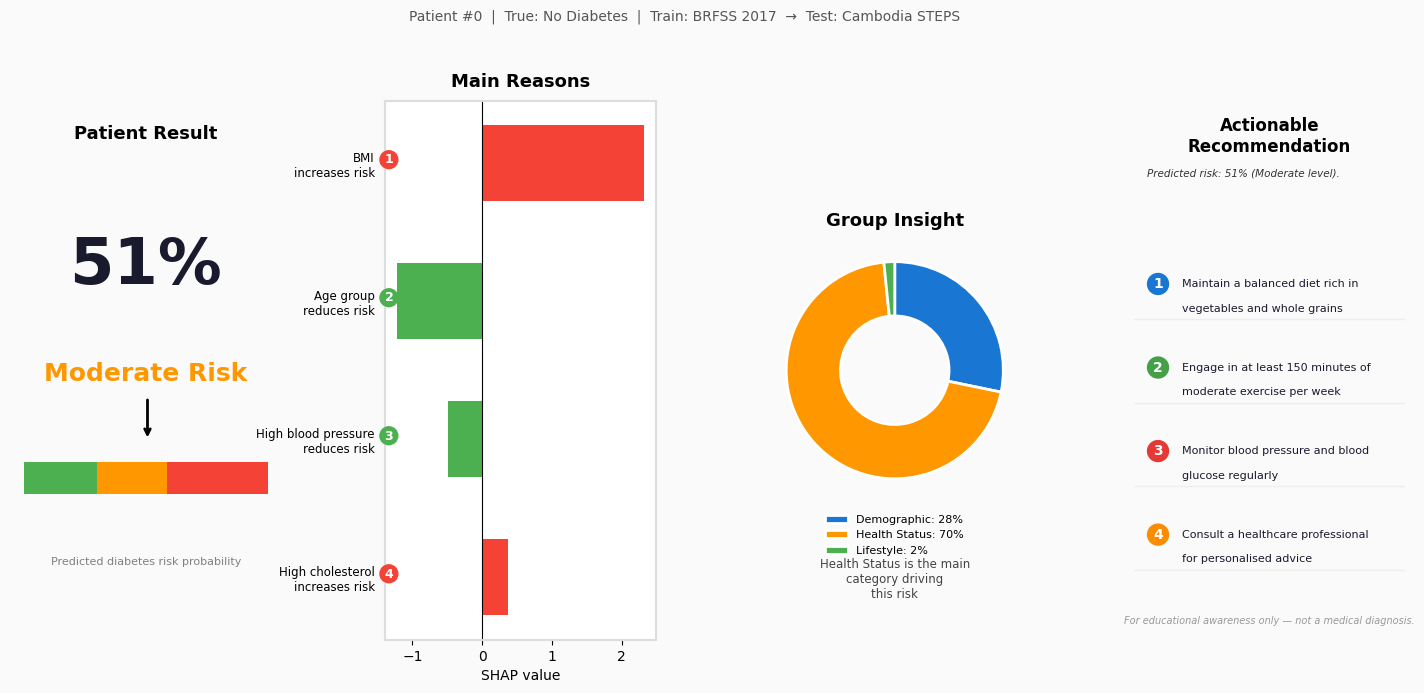

In [ ]:
def patient_dashboard(patient_idx, use_gemini=True):
    prob       = float(proba_test[patient_idx])
    risk       = risk_label(prob)
    true_label = int(y_test.values[patient_idx])
    shap_vals  = sv.values[patient_idx]
    row        = X_test_raw.iloc[patient_idx]

    order     = np.argsort(np.abs(shap_vals))[::-1]
    top_feats = [ALIGNED_FEATURES[i] for i in order[:4]]
    top_vals  = [shap_vals[i] for i in order[:4]]

    gc = {}
    for grp, feats in FEATURE_GROUPS.items():
        idxs = [ALIGNED_FEATURES.index(f) for f in feats if f in ALIGNED_FEATURES]
        gc[grp] = float(np.abs(shap_vals[idxs]).sum())
    gc_total = sum(gc.values()) or 1
    gc_pct   = {k: v/gc_total*100 for k, v in gc.items()}

    risk_feats = [FEATURE_LABELS.get(ALIGNED_FEATURES[i], ALIGNED_FEATURES[i])
                  for i in np.argsort(shap_vals)[::-1][:4] if shap_vals[i] > 0]
    prot_feats = [FEATURE_LABELS.get(ALIGNED_FEATURES[i], ALIGNED_FEATURES[i])
                  for i in np.argsort(shap_vals)[:4] if shap_vals[i] < 0]
    patient_profile = {
        'Age_group': int(row.get('Age', 0)),
        'BMI':       round(float(row.get('BMI', 0)), 1),
        'HighBP':    int(row.get('HighBP', 0)),
        'PhysActive':int(row.get('PhysActivity', 0)),
        'Smoker':    int(row.get('Smoker', 0)),
    }

    if use_gemini and gemini_client:
        gem = get_gemini_recommendations(prob, risk, patient_profile, risk_feats, prot_feats)
    else:
        gem = {
            'explanation': f'Predicted diabetes risk: {prob*100:.0f}% ({risk} level).',
            'recommendations': [
                'Maintain a balanced diet with more vegetables and whole grains',
                'Exercise at least 150 minutes per week',
                'Monitor blood pressure and blood sugar regularly',
                'Consult a healthcare professional for personalised advice',
            ],
            'safety_reminder': 'For educational awareness only — not a medical diagnosis.',
        }
    recs = gem.get('recommendations', [])[:4]

    risk_color   = RISK_COLORS[risk]
    group_colors = ['#1976D2', '#FF9800', '#4CAF50']  # Demographic, Health Status, Lifestyle
    rec_colors   = ['#1976D2','#43A047','#E53935','#FB8C00']

    fig = plt.figure(figsize=(18, 7))
    fig.patch.set_facecolor('#FAFAFA')
    gs  = fig.add_gridspec(1, 4, wspace=0.38)

    ax1 = fig.add_subplot(gs[0]); ax1.set_facecolor('white'); ax1.axis('off')
    ax1.text(0.5, 0.93, 'Patient Result', ha='center', fontsize=13, fontweight='bold', transform=ax1.transAxes)
    ax1.text(0.5, 0.66, f'{prob*100:.0f}%', ha='center', fontsize=46, fontweight='bold', color='#1A1A2E', transform=ax1.transAxes)
    ax1.text(0.5, 0.48, f'{risk} Risk', ha='center', fontsize=18, fontweight='bold', color=risk_color, transform=ax1.transAxes)
    for x0, x1c, c in [(0.05,0.32,'#4CAF50'),(0.32,0.58,'#FF9800'),(0.58,0.95,'#F44336')]:
        ax1.barh(0.30, x1c-x0, left=x0, height=0.06, color=c, transform=ax1.transAxes)
    needle = min(0.05 + prob*0.90, 0.93)
    ax1.annotate('', xy=(needle, 0.37), xytext=(needle, 0.45),
                 xycoords='axes fraction', textcoords='axes fraction',
                 arrowprops=dict(arrowstyle='->', color='black', lw=2))
    ax1.text(0.5, 0.14, 'Predicted diabetes risk probability', ha='center', fontsize=8, color='gray', transform=ax1.transAxes)
    ax1.set_xlim(0,1); ax1.set_ylim(0,1)
    for sp in ax1.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    ax2 = fig.add_subplot(gs[1]); ax2.set_facecolor('white')
    bar_colors = ['#F44336' if v > 0 else '#4CAF50' for v in top_vals]
    y_pos = list(range(len(top_feats)-1, -1, -1))
    ax2.barh(y_pos, top_vals, color=bar_colors, height=0.55)
    labels = [f'{FEATURE_LABELS.get(f,f)}\n{"increases" if v>0 else "reduces"} risk'
              for f, v in zip(top_feats, top_vals)]
    ax2.set_yticks(y_pos); ax2.set_yticklabels(labels, fontsize=8.5)
    ax2.axvline(0, color='black', linewidth=0.8)
    ax2.set_title('Main Reasons', fontsize=13, fontweight='bold', pad=10)
    ax2.set_xlabel('SHAP value')
    for i, y in enumerate(y_pos):
        cc = '#F44336' if top_vals[i] > 0 else '#4CAF50'
        ax2.annotate(str(i+1), xy=(ax2.get_xlim()[0], y), fontsize=9, color='white', fontweight='bold',
                     bbox=dict(boxstyle='circle,pad=0.25', fc=cc, ec='none'))
    for sp in ax2.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    ax3 = fig.add_subplot(gs[2]); ax3.set_facecolor('white')
    grp_names = list(gc_pct.keys()); grp_vals = [gc_pct[g] for g in grp_names]
    wedges, _ = ax3.pie(grp_vals, colors=group_colors, startangle=90, counterclock=False,
                        wedgeprops={'width':0.5,'edgecolor':'white','linewidth':2})
    ax3.legend(wedges, [f'{g}: {v:.0f}%' for g,v in zip(grp_names,grp_vals)],
               loc='lower center', bbox_to_anchor=(0.5,-0.22), fontsize=8, frameon=False)
    ax3.set_title('Group Insight', fontsize=13, fontweight='bold')
    top_grp = max(gc_pct, key=gc_pct.get)
    ax3.text(0.5, -0.34, f'{top_grp} is the main\ncategory driving\nthis risk',
             ha='center', fontsize=8.5, color='#444444', transform=ax3.transAxes)
    for sp in ax3.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    ax4 = fig.add_subplot(gs[3]); ax4.set_facecolor('white'); ax4.axis('off')
    ax4.text(0.5, 0.97, 'Actionable\nRecommendation',
             ha='center', va='top', fontsize=12, fontweight='bold', transform=ax4.transAxes)
    explanation = gem.get('explanation','')
    for li, line in enumerate(textwrap.wrap(explanation, 42)[:3]):
        ax4.text(0.05, 0.86-li*0.055, line, ha='left', fontsize=7.5,
                 color='#333333', style='italic', transform=ax4.transAxes)
    for i, rec in enumerate(recs):
        yr = 0.66 - i*0.155
        ax4.text(0.09, yr, str(i+1), ha='center', va='center',
                 fontsize=10, color='white', fontweight='bold', transform=ax4.transAxes,
                 bbox=dict(boxstyle='circle,pad=0.3', fc=rec_colors[i], ec='none'))
        for wi, wl in enumerate(textwrap.wrap(rec, 35)[:2]):
            ax4.text(0.18, yr-wi*0.045, wl, ha='left', va='center',
                     fontsize=8, color='#1A1A2E', transform=ax4.transAxes)
        ax4.plot([0,1],[yr-0.065,yr-0.065],'#EEEEEE', lw=1, transform=ax4.transAxes)
    ax4.text(0.5, 0.03, gem.get('safety_reminder','')[:70],
             ha='center', fontsize=7, color='#999999', style='italic', transform=ax4.transAxes)
    for sp in ax4.spines.values(): sp.set_edgecolor('#DDDDDD'); sp.set_linewidth(1.5)

    fig.suptitle(
        f'Patient #{patient_idx}  |  True: {["No Diabetes","Diabetes"][true_label]}  |  '
        f'Train: BRFSS 2017  →  Test: Cambodia STEPS',
        fontsize=10, color='#555555', y=1.01
    )
    plt.show()
    return prob, risk

high_idx = int(np.argmax(proba_test))
print(f'High-risk patient: #{high_idx}')
patient_dashboard(high_idx)

mod_mask = (proba_test >= chosen_threshold) & (proba_test < 0.70)
if mod_mask.any():
    patient_dashboard(int(np.where(mod_mask)[0][0]))

  FINAL SUMMARY — BRFSS 2017 -> Cambodia STEPS
  Train / Val   : BRFSS 2017 only  (80/20 stratified)
  Test          : Cambodia STEPS (873 records, used once)
  Features      : 11  ['Sex', 'Age', 'Education', 'HighBP', 'HighChol', 'BMI', 'Smoker', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump']
  Candidates    : ['Logistic Regression', 'Random Forest', 'XGBoost', 'LightGBM', 'CatBoost', 'Soft Voting']

  Best model        : Soft Voting
  Best hyperparams  : (Soft Voting — ensemble of top-3 by F1)
  Best threshold    : 0.43
  Recall >= 0.7 rule: MET

  Validation metrics (selected model @ chosen threshold):
    Recall      0.7046  <- clinical
    Precision   0.3322
    Accuracy    0.7269
    F1          0.4515  <- selection

  Cambodia STEPS final test metrics:
    Recall      0.7623  <- clinical
    Precision   0.2058
    Accuracy    0.5556
    F1          0.3240  <- selection

  Validation confusion matrix (rows=true, cols=pred) [No, Diab]:
    [[33890 12462]
     [ 2599  61

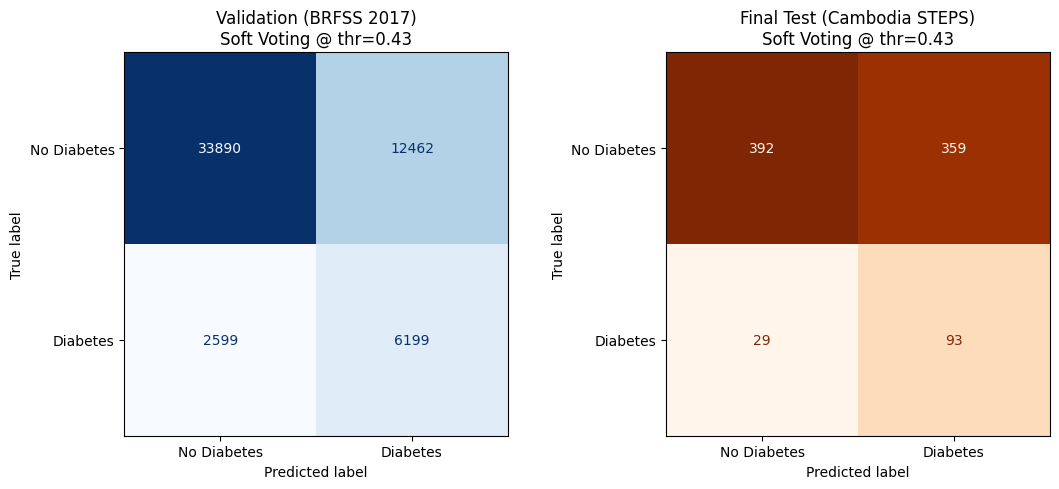


  Risk tier breakdown (STEPS test):
Risk Level
High        173
Moderate    401
Low         299
Name: count, dtype: int64


In [ ]:
print('=' * 64)
print('  FINAL SUMMARY — BRFSS 2017 -> Cambodia STEPS')
print('=' * 64)
print(f'  Train / Val   : BRFSS 2017 only  (80/20 stratified)')
print(f'  Test          : Cambodia STEPS (873 records, used once)')
print(f'  Features      : {len(ALIGNED_FEATURES)}  {ALIGNED_FEATURES}')
print(f'  Candidates    : {list(final_models.keys())}')
print()
print(f'  Best model        : {best_name}')
print(f'  Best hyperparams  : {best_params.get(best_name, "(Soft Voting — ensemble of top-3 by F1)")}')
print(f'  Best threshold    : {chosen_threshold:.2f}')
print(f'  Recall >= {RECALL_FLOOR} rule: {"MET" if recall_met else "NOT MET (fallback to max-F1)"}')
print()

print('  Validation metrics (selected model @ chosen threshold):')
for k in ['Recall', 'Precision', 'Accuracy', 'F1']:
    note = '  <- clinical' if k == 'Recall' else ('  <- selection' if k == 'F1' else '')
    print(f'    {k:<11s} {best_row[k]:.4f}{note}')
print()
print('  Cambodia STEPS final test metrics:')
for k in ['Recall', 'Precision', 'Accuracy', 'F1']:
    note = '  <- clinical' if k == 'Recall' else ('  <- selection' if k == 'F1' else '')
    print(f'    {k:<11s} {test_metrics[k]:.4f}{note}')
print()

# ── Confusion matrices: validation vs final test ─────────────────────────────
val_pred = (proba_val >= chosen_threshold).astype(int)
cm_val   = confusion_matrix(y_val, val_pred)
cm_test  = confusion_matrix(y_test, y_pred)

print('  Validation confusion matrix (rows=true, cols=pred) [No, Diab]:')
print('    ' + str(cm_val).replace('\n', '\n    '))
print('  Cambodia STEPS confusion matrix (rows=true, cols=pred) [No, Diab]:')
print('    ' + str(cm_test).replace('\n', '\n    '))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ConfusionMatrixDisplay(cm_val, display_labels=['No Diabetes', 'Diabetes']).plot(
    ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Validation (BRFSS 2017)\n{best_name} @ thr={chosen_threshold:.2f}')
ConfusionMatrixDisplay(cm_test, display_labels=['No Diabetes', 'Diabetes']).plot(
    ax=axes[1], cmap='Oranges', colorbar=False)
axes[1].set_title(f'Final Test (Cambodia STEPS)\n{best_name} @ thr={chosen_threshold:.2f}')
plt.tight_layout(); plt.show()

print('\n  Risk tier breakdown (STEPS test):')
print(test_report['Risk Level'].value_counts().reindex(['High', 'Moderate', 'Low']))

## 15. Save Model & Artefacts

In [ ]:
joblib.dump(best_model,       'best_model_2017.pkl')
joblib.dump(scaler,           'scaler_2017.pkl')
joblib.dump(chosen_threshold, 'threshold_2017.pkl')
joblib.dump(ALIGNED_FEATURES, 'feature_names_2017.pkl')
print(f'Saved: best_model_2017.pkl    ({best_name})')
print(f'Saved: scaler_2017.pkl')
print(f'Saved: threshold_2017.pkl     ({chosen_threshold:.2f})')
print(f'Saved: feature_names_2017.pkl ({len(ALIGNED_FEATURES)} features)')

# XGBoost SHAP proxy — the deployed model is a Soft Voting ensemble (not directly
# SHAP-explainable), so we also save the tuned XGBoost member as a tree-based proxy
# for the demo app's "Why this prediction?" SHAP panel.
if 'XGBoost' in individual_models:
    joblib.dump(individual_models['XGBoost'], 'xgboost_proxy_2017.pkl')
    print(f'Saved: xgboost_proxy_2017.pkl  (SHAP proxy — XGBoost ensemble member)')
else:
    print('XGBoost not found in individual_models — SHAP proxy not saved.')

Saved: best_model_2017.pkl    (Soft Voting)
Saved: scaler_2017.pkl
Saved: threshold_2017.pkl     (0.43)
Saved: feature_names_2017.pkl (11 features)
Saved: xgboost_proxy_2017.pkl  (SHAP proxy — XGBoost ensemble member)
